**Week 8 - Evaluation Expression**

* Compute metrics beyond R^2: MAPE and MdAPE
* Summarize insights (e.g., which price bands perform better)
* **Deliverable**: 06_evaluation.ipynb + metrics_summary.csv


In [ ]:
import os
import glob
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import lightgbm as lgb
import xgboost as xgb
from sklearn.model_selection import KFold
from sklearn.neighbors import BallTree
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

try:
    import geopandas as gpd
except ImportError:
    import subprocess, sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "geopandas"])
    import geopandas as gpd

warnings.filterwarnings("ignore")

from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:
CSV_DIR = "/content/drive/MyDrive/csv"                # the monthly CRMLSSold files (only used if the unscaled file has to be built)
DATA_DIR = "/content/drive/MyDrive/output"            # same folder as Weeks 3-7
DISTRICT_FILE = "/content/drive/MyDrive/school_districts/california_school_district_areas_2024-25.geojson"

X_MONTHS = 24           # training window from Week 3
SEED = 42

DT_DEPTH = 20           # Decision Tree depth from Week 5
RF_TREES = 100          # Random Forest size from Week 5 (lower to 50 if it runs too slowly)

# the tuned settings that won in Week 7
LGB_PARAMS = dict(max_depth=6, learning_rate=0.10, n_estimators=760, num_leaves=63)
XGB_PARAMS = dict(max_depth=8, learning_rate=0.05, n_estimators=759)


In [ ]:
def build_unscaled_file(out_path):
    needed = ["ClosePrice", "CloseDate", "PropertyType", "PropertySubType", "LivingArea", "BedroomsTotal",
              "BathroomsTotalInteger", "LotSizeSquareFeet", "YearBuilt", "City", "PostalCode",
              "Latitude", "Longitude", "latfilled", "lonfilled"]

    files = glob.glob(os.path.join(CSV_DIR, "CRMLSSold*.csv"))
    print(f"Found {len(files)} files")
    raw = pd.concat([pd.read_csv(f, usecols=lambda c: c in needed, low_memory=False) for f in files],
                    ignore_index=True)
    print(f"Loaded {len(raw):,} rows")

    raw = raw[(raw["PropertyType"] == "Residential") & (raw["PropertySubType"] == "SingleFamilyResidence")].copy()
    raw["CloseDate"] = pd.to_datetime(raw["CloseDate"], errors="coerce")
    print(f"Rows after filtering to Residential / SingleFamilyResidence: {len(raw):,}")

    # impossible values -> missing (same rules as Week 3)
    bad_rows = {
        "ClosePrice":            (raw["ClosePrice"] <= 10_000) | (raw["ClosePrice"] > 20_000_000),
        "LivingArea":            (raw["LivingArea"] <= 100) | (raw["LivingArea"] > 15_000),
        "BedroomsTotal":         (raw["BedroomsTotal"] <= 0) | (raw["BedroomsTotal"] > 12),
        "BathroomsTotalInteger": (raw["BathroomsTotalInteger"] <= 0) | (raw["BathroomsTotalInteger"] > 12),
        "LotSizeSquareFeet":     (raw["LotSizeSquareFeet"] <= 100) | (raw["LotSizeSquareFeet"] > 1_000_000),
        "YearBuilt":             (raw["YearBuilt"] < 1800) | (raw["YearBuilt"] > 2026),
    }
    for col, mask in bad_rows.items():
        print(f"{col}: {mask.sum():,} impossible values set to missing")
        raw.loc[mask, col] = np.nan

    # drop rows with no target, fill the rest (same as Week 3)
    raw = raw[raw["ClosePrice"].notna()].copy()
    for col in ["LivingArea", "BedroomsTotal", "BathroomsTotalInteger", "LotSizeSquareFeet", "YearBuilt"]:
        raw[col] = raw[col].fillna(raw[col].median())
    raw["City"] = raw["City"].fillna("Unknown")
    raw["PostalCode"] = raw["PostalCode"].fillna("Unknown")

    # same split as Week 3: test = most recent month, train = the X_MONTHS months before it
    month = raw["CloseDate"].dt.to_period("M")
    test_month = month.max()
    window_start = (test_month - X_MONTHS).to_timestamp()
    window_end = test_month.to_timestamp()
    test_part = raw[month == test_month]
    train_part = raw[(raw["CloseDate"] >= window_start) & (raw["CloseDate"] < window_end)]

    keep = [c for c in ["ClosePrice", "CloseDate", "LivingArea", "BedroomsTotal", "BathroomsTotalInteger",
                        "LotSizeSquareFeet", "YearBuilt", "City", "PostalCode",
                        "Latitude", "Longitude", "latfilled", "lonfilled"] if c in raw.columns]
    out = pd.concat([train_part[keep].assign(split="train"), test_part[keep].assign(split="test")],
                    ignore_index=True)

    os.makedirs(os.path.dirname(out_path), exist_ok=True)
    out.to_csv(out_path, index=False)
    print(f"Saved {out_path} ({len(out):,} rows). Test month: {test_month}")


In [ ]:
unscaled_path = os.path.join(DATA_DIR, "cleaned_data_unscaled.csv")

if os.path.exists(unscaled_path):
    print("Found cleaned_data_unscaled.csv")
else:
    print("cleaned_data_unscaled.csv not found, so I'm building it from the raw files...")
    build_unscaled_file(unscaled_path)

data = pd.read_csv(unscaled_path)
data["CloseDate"] = pd.to_datetime(data["CloseDate"])

print("\nRows:", len(data))
print(data["split"].value_counts())
data.head()


Found cleaned_data_unscaled.csv

Rows: 276550
split
train    265372
test      11178
Name: count, dtype: int64


,ClosePrice,CloseDate,LivingArea,BedroomsTotal,BathroomsTotalInteger,LotSizeSquareFeet,YearBuilt,City,PostalCode,Latitude,Longitude,latfilled,lonfilled,split
0,1370000.0,2026-03-23,1860.0,4.0,3.0,6390.0,1976.0,San Jose,95136,37.272409,-121.876701,NaN,NaN,train
1,7200000.0,2026-03-27,2972.0,4.0,5.0,5625.0,1902.0,Palo Alto,94301,37.440060,-122.154345,NaN,NaN,train
2,1240000.0,2026-03-31,1980.0,3.0,2.0,5000.0,1973.0,La Palma,90623,33.852090,-118.045009,NaN,NaN,train
3,2650000.0,2026-03-30,2973.0,4.0,4.0,10454.0,2006.0,Scotts Valley,95066,37.072914,-122.003413,NaN,NaN,train
4,830000.0,2026-03-31,1116.0,3.0,2.0,6285.0,1944.0,Lakewood,90712,33.862645,-118.140949,NaN,NaN,train


In [ ]:
numeric_base = ["LivingArea", "BedroomsTotal", "BathroomsTotalInteger", "LotSizeSquareFeet", "YearBuilt"]

print("Missing values in the numeric columns:")
print(data[numeric_base + ["ClosePrice"]].isna().sum())
print("\nMissing City / PostalCode:", data["City"].isna().sum(), "/", data["PostalCode"].isna().sum())

df = data.copy()      # I'll add the new columns to this copy
df["City"] = df["City"].fillna("Unknown")
df["PostalCode"] = df["PostalCode"].fillna("Unknown")


Missing values in the numeric columns:
LivingArea               0
BedroomsTotal            0
BathroomsTotalInteger    0
LotSizeSquareFeet        0
YearBuilt                0
ClosePrice               0
dtype: int64

Missing City / PostalCode: 0 / 0


In [ ]:
df["bed_bath_ratio"] = df["BedroomsTotal"] / df["BathroomsTotalInteger"]

df["property_age"] = df["CloseDate"].dt.year - df["YearBuilt"]
print("Homes with a negative age (sold before the build year):", (df["property_age"] < 0).sum())
df["property_age"] = df["property_age"].clip(lower=0)

# a few more size features built from the same columns
df["sqft_per_bedroom"] = df["LivingArea"] / df["BedroomsTotal"]      # roomy bedrooms vs. cramped ones
df["lot_to_living"] = df["LotSizeSquareFeet"] / df["LivingArea"]     # how much land a home has compared to its size
df["total_rooms"] = df["BedroomsTotal"] + df["BathroomsTotalInteger"]

df[["bed_bath_ratio", "property_age", "sqft_per_bedroom", "lot_to_living", "total_rooms"]].describe().round(2)


Homes with a negative age (sold before the build year): 26


,bed_bath_ratio,property_age,sqft_per_bedroom,lot_to_living,total_rooms
count,276550.00,276550.00,276550.00,276550.00,276550.00
mean,1.46,49.41,579.11,8.81,6.11
std,0.47,27.59,195.31,33.44,1.86
min,0.25,0.00,35.00,0.04,2.00
25%,1.00,27.00,447.00,2.99,5.00
50%,1.50,49.00,540.67,4.22,6.00
75%,1.50,69.00,664.00,5.95,7.00
max,6.00,225.00,4688.00,7820.00,24.00


In [ ]:
def in_california(lat, lon):
    return lat.between(32.0, 42.5) & lon.between(-125.0, -114.0)

df["lat"] = pd.to_numeric(df["Latitude"], errors="coerce")
df["lon"] = pd.to_numeric(df["Longitude"], errors="coerce")
good = in_california(df["lat"], df["lon"])
print(f"Rows with usable Latitude/Longitude: {good.sum():,} of {len(df):,}")

# some files also have latfilled / lonfilled columns, which look like backup coordinates
if {"latfilled", "lonfilled"}.issubset(df.columns):
    df["latfilled"] = pd.to_numeric(df["latfilled"], errors="coerce")
    df["lonfilled"] = pd.to_numeric(df["lonfilled"], errors="coerce")
    can_fill = ~good & in_california(df["latfilled"], df["lonfilled"])
    df.loc[can_fill, "lat"] = df.loc[can_fill, "latfilled"]
    df.loc[can_fill, "lon"] = df.loc[can_fill, "lonfilled"]
    print(f"Recovered {can_fill.sum():,} rows using latfilled/lonfilled")
    good = in_california(df["lat"], df["lon"])

df.loc[~good, ["lat", "lon"]] = np.nan
print(f"Rows with no usable coordinates (will get 'Unknown' district): {(~good).sum():,} ({(~good).mean():.1%})")
df["lat"] = df["lat"].astype(float)
df["lon"] = df["lon"].astype(float)


Rows with usable Latitude/Longitude: 275,792 of 276,550
Recovered 0 rows using latfilled/lonfilled
Rows with no usable coordinates (will get 'Unknown' district): 758 (0.3%)


In [ ]:
DISTRICT_URL = "https://gis.data.ca.gov/api/download/v1/items/b0e3b936426a47ce9d9a2e77e2bb86cc/geojson?layers=0"

if not os.path.exists(DISTRICT_FILE):
    print("District file not found at:", DISTRICT_FILE)
    print("Trying to download it...")
    try:
        import requests
        r = requests.get(DISTRICT_URL, timeout=600)
        r.raise_for_status()
        if len(r.content) < 100_000:
            raise RuntimeError("response is too small to be the boundary file: " + r.text[:200])
        os.makedirs(os.path.dirname(DISTRICT_FILE), exist_ok=True)
        with open(DISTRICT_FILE, "wb") as f:
            f.write(r.content)
        print("Downloaded.")
    except Exception as e:
        raise FileNotFoundError(
            f"Could not download the district file ({e}). Download the Shapefile or GeoJSON from the data.ca.gov "
            f"link in the task doc, upload it to Drive, and set DISTRICT_FILE to its path.")

districts = gpd.read_file(DISTRICT_FILE)
print("District polygons:", len(districts))
print("Columns:", districts.columns.tolist())
print("Coordinate system:", districts.crs)
districts.drop(columns="geometry").head()


District polygons: 937
Columns: ['OBJECTID', 'Year', 'FedID', 'CDCode', 'CDSCode', 'CountyName', 'DistrictName', 'DistrictType', 'GradeLow', 'GradeHigh', 'GradeLowCensus', 'GradeHighCensus', 'AssistStatus', 'CongressUS', 'SenateCA', 'AssemblyCA', 'UpdateNotes', 'EnrollTotal', 'EnrollCharter', 'EnrollNonCharter', 'AAcount', 'AApct', 'AIcount', 'AIpct', 'AScount', 'ASpct', 'FIcount', 'FIpct', 'HIcount', 'HIpct', 'PIcount', 'PIpct', 'WHcount', 'WHpct', 'MRcount', 'MRpct', 'NRcount', 'NRpct', 'ELcount', 'ELpct', 'FOScount', 'FOSpct', 'HOMcount', 'HOMpct', 'MIGcount', 'MIGpct', 'SWDcount', 'SWDpct', 'SEDcount', 'SEDpct', 'DistrctAreaSqMi', 'Shape__Area', 'Shape__Length', 'geometry']
Coordinate system: EPSG:4326


,OBJECTID,Year,FedID,CDCode,CDSCode,CountyName,DistrictName,DistrictType,GradeLow,GradeHigh,...,HOMpct,MIGcount,MIGpct,SWDcount,SWDpct,SEDcount,SEDpct,DistrctAreaSqMi,Shape__Area,Shape__Length
0,1,2024-25,0601770,0161119,01611190000000,Alameda,Alameda Unified,Unified,PK,12,...,0.7,0,0.0,1356,12.6,3958,36.7,11.248939,4.755489e+07,56522.982683
1,2,2024-25,0601860,0161127,01611270000000,Alameda,Albany City Unified,Unified,PK,12,...,0.6,0,0.0,357,9.7,1184,32.1,1.789984,7.096327e+06,12696.382797
2,3,2024-25,0604740,0161143,01611430000000,Alameda,Berkeley Unified,Unified,PK,12,...,2.1,0,0.0,1111,12.1,2686,29.3,10.434329,4.364648e+07,43695.341538
3,4,2024-25,0607800,0161150,01611500000000,Alameda,Castro Valley Unified,Unified,PK,12,...,1.3,0,0.0,1113,11.6,3728,39.0,66.885571,2.838285e+08,142492.767565
4,5,2024-25,0612630,0161168,01611680000000,Alameda,Emery Unified,Unified,PK,12,...,2.5,0,0.0,81,13.7,412,69.8,1.273929,5.363392e+06,13741.272894


In [ ]:
def find_col(gdf, wanted):
    wanted = wanted.lower()
    for c in gdf.columns:
        c_low = c.lower()
        if c_low == wanted or (len(c_low) >= 8 and wanted.startswith(c_low)):   # shapefiles cut names to 10 characters
            return c
    return None

name_col = find_col(districts, "DistrictName")
type_col = find_col(districts, "DistrictType")
code_col = find_col(districts, "CDCode")
print("Name column:", name_col, "| Type column:", type_col, "| Code column:", code_col)
if name_col is None and code_col is None:
    raise ValueError("Couldn't find the district name or code columns. Look at the Columns list above and set them by hand.")
key_col = code_col if code_col is not None else name_col

# keep the unified + elementary districts, drop the overlapping high school ones
if type_col is not None:
    print(districts[type_col].value_counts())
    primary = districts[~districts[type_col].astype(str).str.contains("high", case=False, na=False)].copy()
else:
    print("No district type column, so using all polygons.")
    primary = districts.copy()
print(f"Using {len(primary)} polygons (high school districts removed)")

primary = primary[primary.geometry.notna() & ~primary.geometry.is_empty].copy()
if primary.crs is None:
    primary = primary.set_crs(epsg=4326)
primary = primary.to_crs(epsg=4326)          # same coordinate system as latitude/longitude

broken = ~primary.geometry.is_valid
if broken.any():
    primary.loc[broken, "geometry"] = primary.loc[broken, "geometry"].buffer(0)   # standard fix for invalid polygons


# extra district columns that come with the boundary file (these describe the district, not the house)
district_attr_map = {}
for wanted, new_name in [("SEDpct", "District_SEDpct"), ("ELpct", "District_ELpct"), ("EnrollTotal", "District_Enroll")]:
    found = find_col(districts, wanted)
    if found is not None and found in primary.columns:
        district_attr_map[found] = new_name
print("District attribute columns found:", district_attr_map)


Name column: DistrictName | Type column: DistrictType | Code column: CDCode
DistrictType
Elementary    516
Unified       345
High           76
Name: count, dtype: int64
Using 861 polygons (high school districts removed)
District attribute columns found: {'SEDpct': 'District_SEDpct', 'ELpct': 'District_ELpct', 'EnrollTotal': 'District_Enroll'}


In [ ]:
have_coords = df[df["lat"].notna()]
points = gpd.GeoDataFrame(have_coords[["lat", "lon"]],
                          geometry=gpd.points_from_xy(have_coords["lon"], have_coords["lat"]),
                          crs="EPSG:4326")

start = time.time()
attr_cols = [c for c in district_attr_map if c != key_col]
joined = gpd.sjoin(points, primary[[key_col] + attr_cols + ["geometry"]], how="left", predicate="within")
print(f"Spatial join took {time.time() - start:.0f} seconds")

n_multi = joined.index.duplicated().sum()
joined = joined[~joined.index.duplicated(keep="first")]

df["SchoolDistrict"] = joined[key_col]
df["SchoolDistrict"] = df["SchoolDistrict"].fillna("Unknown").astype(str)
for col in attr_cols:
    df[district_attr_map[col]] = pd.to_numeric(joined[col], errors="coerce")   # NaN for homes with no district

print(f"Points that fell in more than one polygon (kept the first): {n_multi:,}")
print(f"Homes matched to a district: {(df['SchoolDistrict'] != 'Unknown').mean():.1%}")
print(f"Different districts in the data: {df['SchoolDistrict'].nunique():,}")


Spatial join took 1 seconds
Points that fell in more than one polygon (kept the first): 1,234
Homes matched to a district: 99.7%
Different districts in the data: 728


In [ ]:
# sanity check: the districts with the most sales, and their median price
name_lookup = primary.drop_duplicates(subset=key_col).set_index(key_col)[name_col] if name_col else None

summary = df.groupby("SchoolDistrict")["ClosePrice"].agg(sales="count", median_price="median")
summary = summary.sort_values("sales", ascending=False).head(10)
if name_lookup is not None:
    summary.insert(0, "district_name", summary.index.map(name_lookup))
summary


,district_name,sales,median_price
SchoolDistrict,,,
1964733,Los Angeles Unified,27262,1160000.0
3768338,San Diego Unified,7433,1192250.0
3066464,Capistrano Unified,4974,1700000.0
3367058,Desert Sands Unified,4836,620000.0
3367173,Palm Springs Unified,4311,700000.0
0161259,Oakland Unified,3625,969000.0
3367033,Corona-Norco Unified,3505,850000.0
1964725,Long Beach Unified,3341,970000.0
3367082,Hemet Unified,3303,476000.0


In [ ]:
city_centers = {
    "Los Angeles": (34.0522, -118.2437), "San Francisco": (37.7749, -122.4194), "San Diego": (32.7157, -117.1611),
    "San Jose": (37.3382, -121.8863), "Sacramento": (38.5816, -121.4944),
}

def haversine_km(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 6371 * 2 * np.arcsin(np.sqrt(a))

dists = np.column_stack([haversine_km(df["lat"].astype(float).values, df["lon"].astype(float).values, la, lo) for la, lo in city_centers.values()])
df["dist_nearest_city_km"] = dists.min(axis=1)       # stays NaN where the coordinates are missing
df["dist_nearest_city_km"].describe().round(1)


,dist_nearest_city_km
count,275792.0
mean,63.7
std,50.0
min,0.0
25%,25.5
50%,50.0
75%,91.0
max,441.0


In [ ]:
train_df = df[df["split"] == "train"].copy()
test_df = df[df["split"] == "test"].copy()

print(f"Test month: {test_df['CloseDate'].dt.to_period('M').max()} ({len(test_df):,} rows)")
print(f"Training window: {train_df['CloseDate'].dt.to_period('M').nunique()} months, {len(train_df):,} rows")


Test month: 2026-09 (11,178 rows)
Training window: 24 months, 265,372 rows


In [ ]:
def target_encode(train_df, apply_df, col, target="ClosePrice", smoothing=20, n_splits=5, seed=42):
    # smoothed average price per category, learned from `source` only
    def encode(source, rows):
        overall = source[target].mean()
        stats = source.groupby(col)[target].agg(["mean", "count"])
        smooth = (stats["count"] * stats["mean"] + smoothing * overall) / (stats["count"] + smoothing)
        return rows[col].map(smooth).fillna(overall).values

    # training rows: out-of-fold, so a home's own price never goes into its own encoding
    train_encoded = np.zeros(len(train_df))
    for fit_idx, enc_idx in KFold(n_splits=n_splits, shuffle=True, random_state=seed).split(train_df):
        train_encoded[enc_idx] = encode(train_df.iloc[fit_idx], train_df.iloc[enc_idx])

    # test rows: use the whole training window
    return train_encoded, encode(train_df, apply_df)


def neighbor_price_features(train_df, apply_df, k=20, n_splits=5, seed=42):
    """For each home: the median price per square foot of its k nearest *training* sales, and that rate times its
    own living area. Training rows are done out-of-fold so a home never sees its own price."""
    ppsf = (train_df["ClosePrice"] / train_df["LivingArea"]).values
    overall = np.median(ppsf)

    def encode(src_idx, rows):
        src = train_df.iloc[src_idx]
        src_ok = pd.to_numeric(src["lat"], errors="coerce").notna().values
        tree = BallTree(np.radians(src.loc[src_ok, ["lat", "lon"]].to_numpy(dtype=float)), metric="haversine")
        src_ppsf = ppsf[src_idx][src_ok]
        out = np.full(len(rows), overall)
        ok = pd.to_numeric(rows["lat"], errors="coerce").notna().values
        if ok.any():
            _, nn = tree.query(np.radians(rows.loc[ok, ["lat", "lon"]].to_numpy(dtype=float)), k=k)
            out[ok] = np.median(src_ppsf[nn], axis=1)
        return out

    train_nn = np.zeros(len(train_df))
    for fit_idx, enc_idx in KFold(n_splits=n_splits, shuffle=True, random_state=seed).split(train_df):
        train_nn[enc_idx] = encode(fit_idx, train_df.iloc[enc_idx])
    apply_nn = encode(np.arange(len(train_df)), apply_df)
    return train_nn, apply_nn


tr = train_df.copy()
te = test_df.copy()

for col, new_col in [("City", "City_freq"), ("PostalCode", "PostalCode_freq"), ("SchoolDistrict", "District_freq")]:
    freq = tr[col].value_counts(normalize=True)
    tr[new_col] = tr[col].map(freq).fillna(0.0)
    te[new_col] = te[col].map(freq).fillna(0.0)

tr["District_te"], te["District_te"] = target_encode(tr, te, "SchoolDistrict")

# target encodings for city and postal code (same out-of-fold method as the district)
tr["City_te"], te["City_te"] = target_encode(tr, te, "City")
tr["PostalCode_te"], te["PostalCode_te"] = target_encode(tr, te, "PostalCode")

# price of nearby sales (takes a minute or two)
start = time.time()
tr["nn_ppsf"], te["nn_ppsf"] = neighbor_price_features(tr, te)
tr["nn_est_price"] = tr["nn_ppsf"] * tr["LivingArea"]
te["nn_est_price"] = te["nn_ppsf"] * te["LivingArea"]
print(f"Neighbor price features took {time.time() - start:.0f} seconds")

# district attributes and distance: fill the gaps with the training medians
district_attr_features = list(district_attr_map.values())
for col in district_attr_features + ["dist_nearest_city_km"]:
    med = tr[col].median()
    tr[col] = tr[col].fillna(med)
    te[col] = te[col].fillna(med)
if "District_Enroll" in district_attr_features:
    tr["District_Enroll"] = np.log1p(tr["District_Enroll"])        # enrollment is very skewed
    te["District_Enroll"] = np.log1p(te["District_Enroll"])

size_features = ["sqft_per_bedroom", "lot_to_living", "total_rooms"]
location_features = ["dist_nearest_city_km", "nn_ppsf", "nn_est_price"]

all_features = numeric_base + ["City_freq", "PostalCode_freq", "bed_bath_ratio", "property_age",
                               "District_freq", "District_te",
                               "City_te", "PostalCode_te"] + size_features + district_attr_features + location_features
print("Training rows:", tr.shape[0], " Test rows:", te.shape[0])


Neighbor price features took 68 seconds
Training rows: 265372  Test rows: 11178


In [ ]:
train, test = tr.copy(), te.copy()
final_features = [c for c in all_features if c != "District_freq"]       # set 8 from Week 6

X_train, X_test = train[final_features], test[final_features]
y_train, y_test = train["ClosePrice"].to_numpy(), test["ClosePrice"].to_numpy()
print("Train rows:", len(train), " Test rows:", len(test), " Features:", len(final_features))
print("Test month:", test["CloseDate"].dt.to_period("M").max())

scaler = StandardScaler().fit(X_train)
X_train_scaled, X_test_scaled = scaler.transform(X_train), scaler.transform(X_test)

models = {
    "Linear Regression": (LinearRegression(), True),
    f"Decision Tree (depth {DT_DEPTH})": (DecisionTreeRegressor(max_depth=DT_DEPTH, random_state=42), False),
    f"Random Forest ({RF_TREES} trees)": (RandomForestRegressor(n_estimators=RF_TREES, min_samples_leaf=5, n_jobs=-1, random_state=42), False),
    "LightGBM (tuned)": (lgb.LGBMRegressor(**LGB_PARAMS, random_state=SEED, n_jobs=-1, verbose=-1), False),
    "XGBoost (tuned)": (xgb.XGBRegressor(**XGB_PARAMS, tree_method="hist", random_state=SEED, n_jobs=-1), False),
}

preds, fitted = {}, {}
for name, (model, use_scaled) in models.items():
    start = time.time()
    Xtr, Xte = (X_train_scaled, X_test_scaled) if use_scaled else (X_train, X_test)
    model.fit(Xtr, y_train)
    preds[name] = model.predict(Xte)
    fitted[name] = model
    print(f"{name:<28} | test R2 = {r2_score(y_test, preds[name]):.4f} | MAE = ${mean_absolute_error(y_test, preds[name]):,.0f} | {time.time() - start:.0f}s")


Train rows: 265372  Test rows: 11178  Features: 21
Test month: 2026-09
Linear Regression            | test R2 = 0.8265 | MAE = $217,324 | 0s
Decision Tree (depth 20)     | test R2 = 0.7533 | MAE = $233,341 | 11s
Random Forest (100 trees)    | test R2 = 0.8570 | MAE = $184,696 | 576s
LightGBM (tuned)             | test R2 = 0.8707 | MAE = $182,482 | 21s
XGBoost (tuned)              | test R2 = 0.8732 | MAE = $177,827 | 37s


In [ ]:
def metrics(y, p, with_r2=False):
    ape = np.abs(p - y) / y
    out = {"n": len(y),
           "MAE": mean_absolute_error(y, p),
           "RMSE": np.sqrt(mean_squared_error(y, p)),
           "MAPE_pct": ape.mean() * 100,
           "MdAPE_pct": np.median(ape) * 100,
           "median_signed_pct_error": np.median((p - y) / y) * 100,
           "within_10pct": (ape <= 0.10).mean() * 100,
           "within_20pct": (ape <= 0.20).mean() * 100}
    if with_r2:
        out["R2"] = r2_score(y, p)
    return out

overall = pd.DataFrame({name: metrics(y_test, p, with_r2=True) for name, p in preds.items()}).T
overall = overall[["R2", "MAE", "RMSE", "MAPE_pct", "MdAPE_pct", "median_signed_pct_error", "within_10pct", "within_20pct"]]
overall = overall.sort_values("MdAPE_pct")
display(overall.round(3))

best_r2 = overall["R2"].idxmax()
best_mape = overall["MAPE_pct"].idxmin()
best_mdape = overall["MdAPE_pct"].idxmin()
print(f"Best R2: {best_r2} | lowest MAPE: {best_mape} | lowest MdAPE: {best_mdape}")
focus = best_r2
print("Detailed analysis below is for:", focus)


,R2,MAE,RMSE,MAPE_pct,MdAPE_pct,median_signed_pct_error,within_10pct,within_20pct
Random Forest (100 trees),0.857,184696.166,491847.381,13.567,8.439,0.907,56.423,81.464
XGBoost (tuned),0.873,177826.964,463049.062,13.223,8.455,0.731,56.379,82.090
LightGBM (tuned),0.871,182482.274,467702.588,13.589,8.837,0.710,55.198,81.025
Decision Tree (depth 20),0.753,233341.081,645978.563,16.536,10.073,0.380,49.669,75.407
Linear Regression,0.826,217324.374,541786.595,17.701,11.841,2.138,43.174,72.500


Best R2: XGBoost (tuned) | lowest MAPE: XGBoost (tuned) | lowest MdAPE: Random Forest (100 trees)
Detailed analysis below is for: XGBoost (tuned)


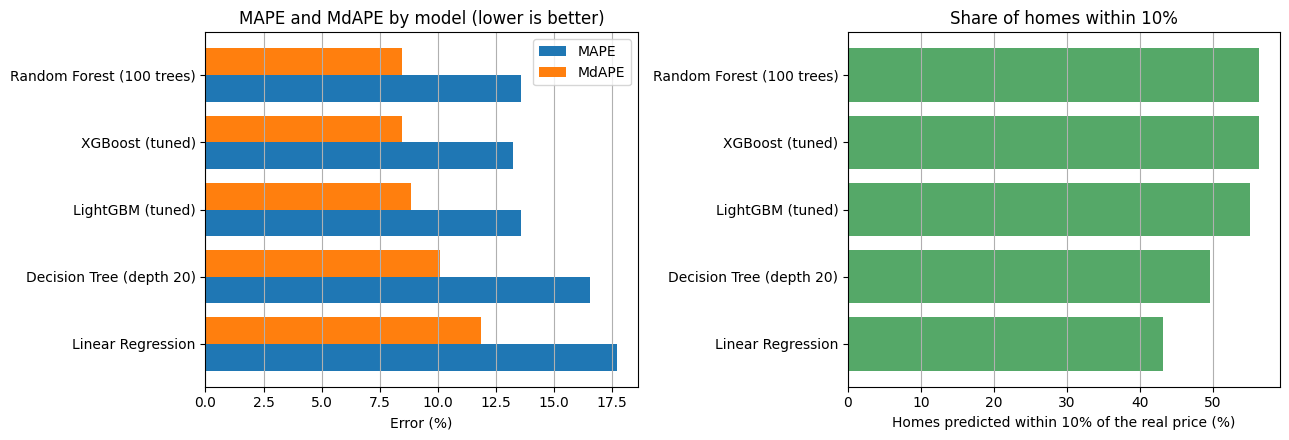

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
order = overall.sort_values("MdAPE_pct", ascending=False)
x = np.arange(len(order))
axes[0].barh(x - 0.2, order["MAPE_pct"], height=0.4, label="MAPE")
axes[0].barh(x + 0.2, order["MdAPE_pct"], height=0.4, label="MdAPE")
axes[0].set_yticks(x)
axes[0].set_yticklabels(order.index)
axes[0].set_xlabel("Error (%)")
axes[0].set_title("MAPE and MdAPE by model (lower is better)")
axes[0].legend()
axes[0].grid(axis="x")

order2 = overall.sort_values("within_10pct")
axes[1].barh(order2.index, order2["within_10pct"], color="#55A868")
axes[1].set_xlabel("Homes predicted within 10% of the real price (%)")
axes[1].set_title("Share of homes within 10%")
axes[1].grid(axis="x")
plt.tight_layout()
plt.show()


In [ ]:
edges = [0, 500_000, 750_000, 1_000_000, 1_500_000, 2_000_000, np.inf]
labels = ["< $500k", "$500k-750k", "$750k-1M", "$1M-1.5M", "$1.5M-2M", "> $2M"]
band = np.asarray(pd.cut(y_test, bins=edges, labels=labels).astype(str))

band_rows = []
for name, p in preds.items():
    for b in labels:
        m = band == b
        if m.sum() == 0:
            continue
        band_rows.append({"model": name, "group": b, **metrics(y_test[m], p[m])})
band_all = pd.DataFrame(band_rows)
band_all["share_of_test_pct"] = band_all["n"] / len(y_test) * 100

band_focus = band_all[band_all["model"] == focus].set_index("group")[
    ["n", "share_of_test_pct", "MAE", "MAPE_pct", "MdAPE_pct", "median_signed_pct_error", "within_10pct", "within_20pct"]]
print("Focus model:", focus)
display(band_focus.round(2))

print("MdAPE (%) by band and model:")
display(band_all.pivot(index="model", columns="group", values="MdAPE_pct")[[l for l in labels if l in band_all["group"].values]].round(1))


Focus model: XGBoost (tuned)


,n,share_of_test_pct,MAE,MAPE_pct,MdAPE_pct,median_signed_pct_error,within_10pct,within_20pct
group,,,,,,,,
< $500k,1626,14.55,59035.67,20.86,8.61,3.79,54.80,75.09
$500k-750k,2510,22.45,67445.23,10.79,7.31,1.24,62.99,86.25
$750k-1M,2291,20.50,89126.53,10.18,7.08,1.13,65.08,88.30
$1M-1.5M,2195,19.64,146352.79,11.84,9.00,0.23,53.99,83.55
$1.5M-2M,1068,9.55,216592.28,12.50,9.55,-0.14,51.50,81.55
> $2M,1488,13.31,649003.02,16.23,12.74,-5.29,40.59,71.37


MdAPE (%) by band and model:


group,< $500k,$500k-750k,$750k-1M,$1M-1.5M,$1.5M-2M,> $2M
model,,,,,,
Decision Tree (depth 20),10.7,8.2,8.3,10.5,10.8,16.2
LightGBM (tuned),9.2,7.4,7.3,9.3,9.9,13.2
Linear Regression,14.7,11.4,10.6,11.0,11.4,14.0
Random Forest (100 trees),8.5,6.8,6.8,9.1,9.9,12.9
XGBoost (tuned),8.6,7.3,7.1,9.0,9.6,12.7


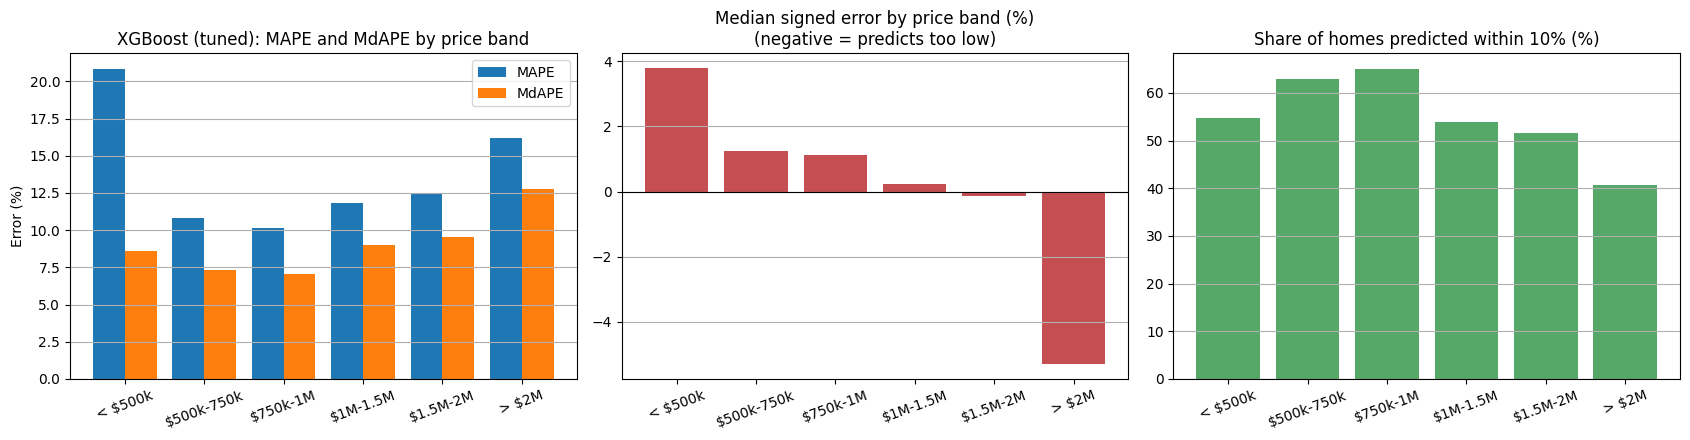

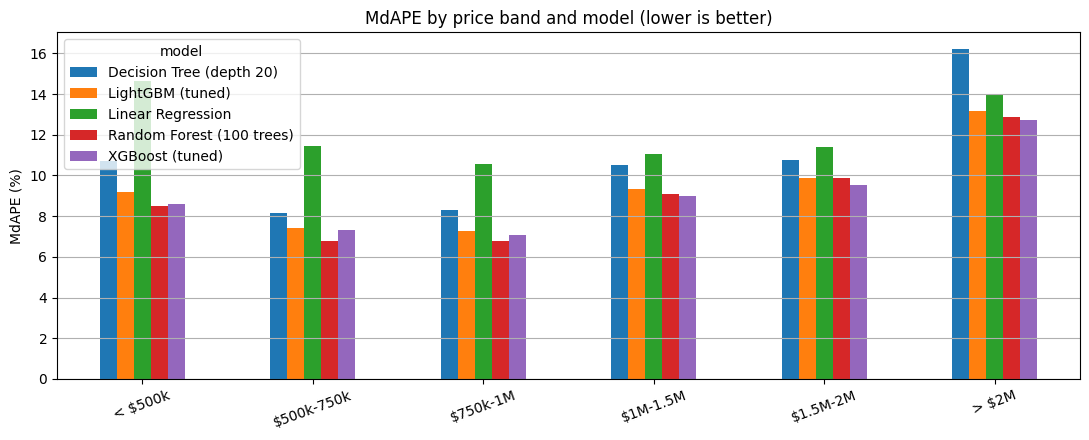

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

x = np.arange(len(band_focus))
axes[0].bar(x - 0.2, band_focus["MAPE_pct"], width=0.4, label="MAPE")
axes[0].bar(x + 0.2, band_focus["MdAPE_pct"], width=0.4, label="MdAPE")
axes[0].set_xticks(x)
axes[0].set_xticklabels(band_focus.index, rotation=20)
axes[0].set_ylabel("Error (%)")
axes[0].set_title(f"{focus}: MAPE and MdAPE by price band")
axes[0].legend()
axes[0].grid(axis="y")

axes[1].bar(band_focus.index, band_focus["median_signed_pct_error"], color="#C44E52")
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].set_title("Median signed error by price band (%)\n(negative = predicts too low)")
axes[1].tick_params(axis="x", rotation=20)
axes[1].grid(axis="y")

axes[2].bar(band_focus.index, band_focus["within_10pct"], color="#55A868")
axes[2].set_title("Share of homes predicted within 10% (%)")
axes[2].tick_params(axis="x", rotation=20)
axes[2].grid(axis="y")

plt.tight_layout()
plt.show()

pivot = band_all.pivot(index="group", columns="model", values="MdAPE_pct").reindex([l for l in labels if l in band_all["group"].values])
pivot.plot(kind="bar", figsize=(11, 4.5))
plt.title("MdAPE by price band and model (lower is better)")
plt.ylabel("MdAPE (%)")
plt.xlabel("")
plt.xticks(rotation=20)
plt.grid(axis="y")
plt.tight_layout()
plt.show()


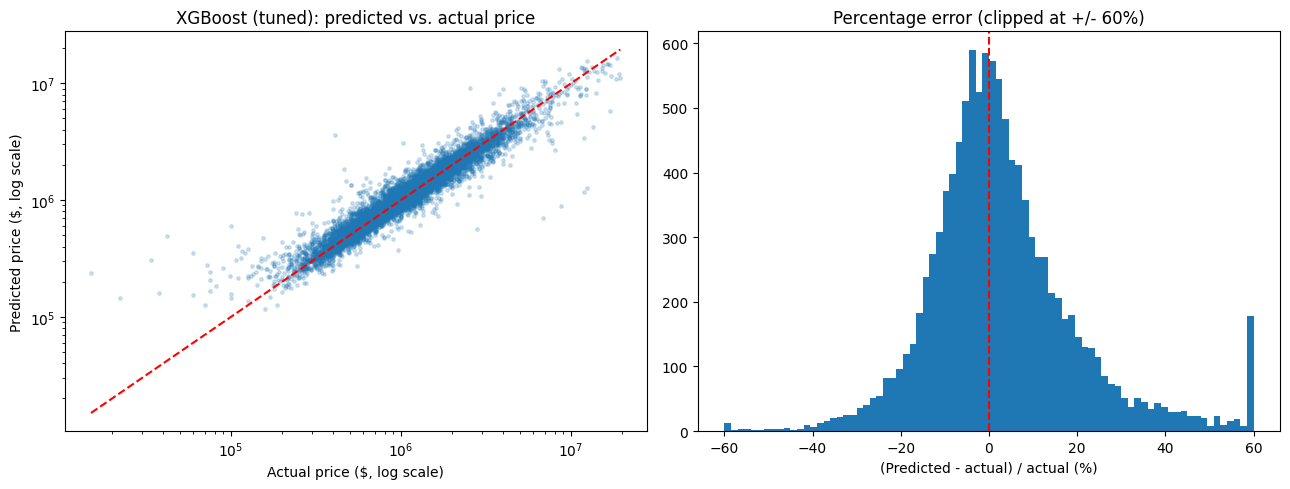

In [ ]:
p = preds[focus]
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

ok = p > 0
axes[0].scatter(y_test[ok], p[ok], alpha=0.2, s=6)
lo, hi = min(y_test.min(), p[ok].min()), max(y_test.max(), p[ok].max())
axes[0].plot([lo, hi], [lo, hi], color="red", linestyle="--")
axes[0].set_xscale("log")
axes[0].set_yscale("log")
axes[0].set_title(f"{focus}: predicted vs. actual price")
axes[0].set_xlabel("Actual price ($, log scale)")
axes[0].set_ylabel("Predicted price ($, log scale)")

pct_error = (p - y_test) / y_test * 100
axes[1].hist(pct_error.clip(-60, 60), bins=80)
axes[1].axvline(0, color="red", linestyle="--")
axes[1].set_title("Percentage error (clipped at +/- 60%)")
axes[1].set_xlabel("(Predicted - actual) / actual (%)")
plt.tight_layout()
plt.show()


In [ ]:
city_test = test["City"].astype(str).to_numpy()
top_cities = pd.Series(city_test).value_counts()
top_cities = top_cities.drop("Unknown", errors="ignore").head(10).index

city_rows = []
for c in top_cities:
    m = city_test == c
    city_rows.append({"group": c, **metrics(y_test[m], preds[focus][m])})
city_df = pd.DataFrame(city_rows).set_index("group")
city_df[["n", "MAE", "MAPE_pct", "MdAPE_pct", "median_signed_pct_error", "within_10pct"]].round(2)


,n,MAE,MAPE_pct,MdAPE_pct,median_signed_pct_error,within_10pct
group,,,,,,
Los Angeles,544,306193.87,15.42,11.61,0.94,44.67
San Diego,383,148562.01,11.12,7.79,1.10,60.05
San Jose,170,230113.98,14.44,11.44,7.31,44.12
Riverside,154,72419.35,9.42,7.33,-1.02,66.23
Oakland,145,201226.19,19.23,15.67,-6.53,31.03
Corona,127,166650.78,11.61,6.62,1.12,64.57
Victorville,122,35084.60,7.31,5.23,-1.17,81.97
Long Beach,121,266741.37,12.56,10.08,-0.64,49.59
Temecula,116,95509.10,9.62,7.83,3.39,64.66


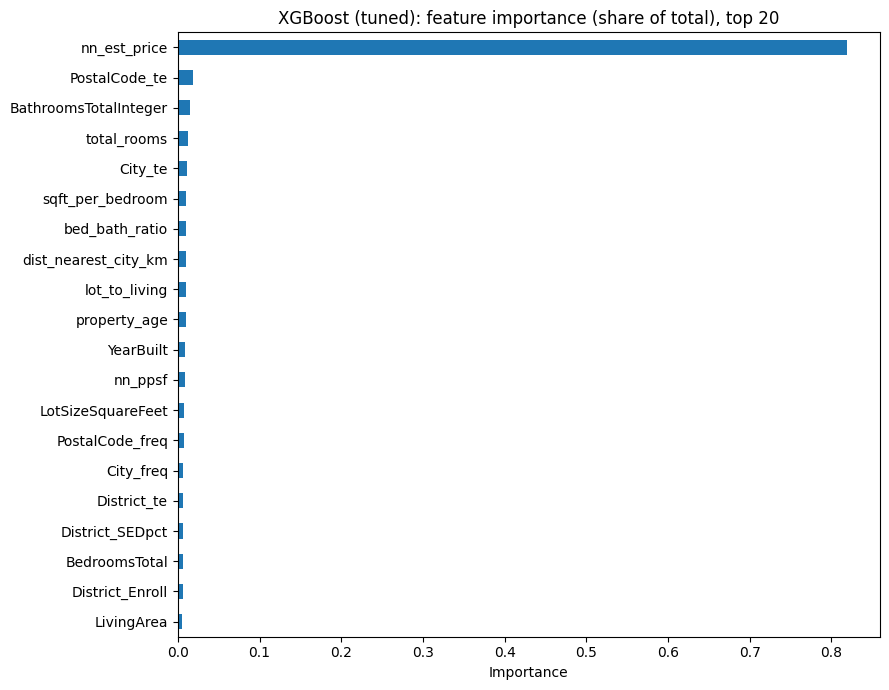

,0
nn_est_price,0.8186
PostalCode_te,0.0181
BathroomsTotalInteger,0.0152
total_rooms,0.0130
City_te,0.0117
sqft_per_bedroom,0.0101
bed_bath_ratio,0.0099
dist_nearest_city_km,0.0099
lot_to_living,0.0095
property_age,0.0095


In [ ]:
model = fitted[focus]
if hasattr(model, "feature_importances_"):
    importance = pd.Series(model.feature_importances_, index=final_features)
else:                      # Linear Regression: use the size of the scaled coefficients
    importance = pd.Series(np.abs(model.coef_), index=final_features)
importance = (importance / importance.sum()).sort_values(ascending=False)

importance.head(20).sort_values().plot(kind="barh", figsize=(9, 7))
plt.title(f"{focus}: feature importance (share of total), top 20")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()
importance.head(10).round(4)


In [ ]:
cols_order = ["section", "model", "group", "n", "share_of_test_pct", "R2", "MAE", "RMSE", "MAPE_pct", "MdAPE_pct",
              "median_signed_pct_error", "within_10pct", "within_20pct"]

part_overall = overall.reset_index().rename(columns={"index": "model"})
part_overall["group"] = "All test homes"
part_overall["n"] = len(y_test)
part_overall.insert(0, "section", "overall")

part_band = band_all.copy()
part_band.insert(0, "section", "price_band")

part_city = city_df.reset_index()
part_city["model"] = focus
part_city.insert(0, "section", "city")

metrics_summary = pd.concat([part_overall, part_band, part_city], ignore_index=True).reindex(columns=cols_order)

os.makedirs(DATA_DIR, exist_ok=True)
metrics_summary.to_csv(os.path.join(DATA_DIR, "metrics_summary.csv"), index=False)
print("Saved metrics_summary.csv:", metrics_summary.shape)
metrics_summary.round(3)


Saved metrics_summary.csv: (45, 13)


,section,model,group,n,share_of_test_pct,R2,MAE,RMSE,MAPE_pct,MdAPE_pct,median_signed_pct_error,within_10pct,within_20pct
0,overall,Random Forest (100 trees),All test homes,11178,NaN,0.857,184696.166,491847.381,13.567,8.439,0.907,56.423,81.464
1,overall,XGBoost (tuned),All test homes,11178,NaN,0.873,177826.964,463049.062,13.223,8.455,0.731,56.379,82.090
2,overall,LightGBM (tuned),All test homes,11178,NaN,0.871,182482.274,467702.588,13.589,8.837,0.710,55.198,81.025
3,overall,Decision Tree (depth 20),All test homes,11178,NaN,0.753,233341.081,645978.563,16.536,10.073,0.380,49.669,75.407
4,overall,Linear Regression,All test homes,11178,NaN,0.826,217324.374,541786.595,17.701,11.841,2.138,43.174,72.500
5,price_band,Linear Regression,< $500k,1626,14.546,NaN,90081.963,177601.779,32.084,14.666,9.859,36.777,60.025
6,price_band,Linear Regression,$500k-750k,2510,22.455,NaN,96519.636,135755.913,15.444,11.441,3.067,44.343,74.821
7,price_band,Linear Regression,$750k-1M,2291,20.496,NaN,121422.588,168820.730,13.964,10.554,1.404,47.708,78.219
8,price_band,Linear Regression,$1M-1.5M,2195,19.637,NaN,180919.901,250424.357,14.619,11.045,1.264,45.740,76.128
9,price_band,Linear Regression,$1.5M-2M,1068,9.554,NaN,260402.411,362356.884,14.969,11.384,1.860,45.412,75.281
